# 1x2 MMI — FDTD/EME Hybrid Simulation

HybridSolver is a generic N-section cascade: any solver type, in any order, any count >= 2.
Here we chain three sections —

    [input section]  ->  [body section]  ->  [output section]

— each independently configurable as FDTD or EME via the METHOD switches below.
HybridSolver itself has no idea any of these are FDTD/EME or that the device is an MMI; it
only knows each solver implements `solve_section()` and combines the resulting per-section
modal transfer matrices by matrix-chain multiplication (the direct generalization of

    alpha_full[m] = sum_n alpha_in[m,n] * alpha_mm[m,n] * alpha_out[m,n]

to non-diagonal per-section matrices and an arbitrary number of sections). The MMI-specific
geometry (tapers, body, output branches) lives entirely in MMI's
`section_prisms`/`section_gds`/`width_at`/`center_at` methods.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from feces import MMI, EMESolver, FDTDSolver, HybridSolver, SOI_160, plot_hybrid_geometry

In [2]:
# Global simulation parameters
RESOLUTION = 40.0   # mesh resolution (pixels/um) — used by both the EME and FDTD sub-solvers
WL_MIN = 1.26       # wavelength sweep start (um)
WL_MAX = 1.36       # wavelength sweep end (um)
N_WL = 11           # number of wavelength points

# Simulation method per section — HybridSolver is solver-agnostic (any mix of
# FDTDSolver/EMESolver, in any order), so each of the three sections can
# independently be "fdtd" or "eme".
INPUT_METHOD = "fdtd"    # "fdtd" or "eme"
BODY_METHOD = "eme"      # "fdtd" or "eme"
OUTPUT_METHOD = "fdtd"   # "fdtd" or "eme"

In [3]:
# 1. Geometry
mmi = MMI(
    n_inputs=1,             # 1x2 splitter
    n_outputs=2,
    mm_length=4.5,
    mm_width=2.0,
    waveguide_width=0.35,
    taper_length=1.0,
    taper_width=0.8,
    waveguide_offset=1.0,
    waveguide_height=0.16,
)
print(f"MMI total length: {mmi.total_length:.2f} um")

MMI total length: 6.50 um


In [4]:
# 2. Configure sub-solvers — one per section, per the METHOD switches above.
#
#    input section  : input access waveguide + input taper + a bit of the
#                      MMI body (enough for a clean interface monitor past
#                      the taper/body cross-section discontinuity)
#    body section   : propagates N modes through the remaining rectangular
#                      MMI body
#    output section : the mirror image of the input section, one instance
#                      per output port

_fdtd_common = dict(
    res=RESOLUTION,
    sim_width=5.0,
    sim_height=1.5,
    dpml=0.5,
    source_margin=0.0,
    monitor_margin=0.25,
    three_d=True,       # full 3-D FDTD: real 160 nm Si core in oxide, PML on all six faces
    material_stack=SOI_160,
    decay_tol=1e-11,
)

N_MODES = 12   # modes carried at the two input/output <-> body interfaces

# The output section's single-mode port (the physical taper tip) sits only
# waveguide_offset=1.0 um from the *other* output branch, which is drawn in
# the same section too (both branches are always physically present).
# half_domain_aperture confines the source/norm aperture to the near half of
# the domain (from the shared y=0 symmetry axis out to the near PML edge),
# so it structurally excludes the opposite branch regardless of how close
# the branches are. The real input port (single waveguide, no neighbor) is
# left untouched — its aperture keeps spanning the full sim_width.


def make_section_solver(method: str, half_domain_aperture: bool = False):
    """Build a solver for one hybrid section. Both FDTDSolver and EMESolver
    implement the same solve_section() interface, so either can fill any
    slot in the chain — num_modes/num_cells/lengths on EMESolver only
    matter for its full-device solve()/solve_sweep(), not solve_section(),
    so placeholder values are fine here."""
    if method == "fdtd":
        kwargs = dict(_fdtd_common)
        kwargs["half_domain_aperture"] = half_domain_aperture
        return FDTDSolver(**kwargs)
    if method == "eme":
        return EMESolver(
            num_modes=[N_MODES], num_cells=[1], lengths=[1.0],
            oxide_width=5.0, oxide_height=1.5, res=RESOLUTION, material_stack=SOI_160,
            mode_solver="meep",  # matches FDTDSolver's own eigenmode basis in this hybrid chain
        )
    raise ValueError(f"unknown method {method!r}, expected 'fdtd' or 'eme'")


# Input section keeps the default (full sim_width) aperture — a single
# waveguide port has no neighbor to avoid. Only the output section, whose
# two branches sit close together, needs the narrower aperture.
input_solver = make_section_solver(INPUT_METHOD)
body_solver = make_section_solver(BODY_METHOD)
output_solver = make_section_solver(OUTPUT_METHOD, half_domain_aperture=True)

In [5]:
# 3. Build HybridSolver — a generic 3-section chain here, but HybridSolver
#    itself works with any solver list of length >= 2, in any order.
half_body = mmi.mm_length / 2
half_total = mmi.total_length / 2
body_stub = 0.25   # um of MMI body folded into each FDTD section, past the
                   # taper/body cross-section discontinuity

boundaries = [
    -half_total,               # physical input port (input taper tip)
    -half_body + body_stub,    # input section <-> body section interface
    +half_body - body_stub,    # body section <-> output section interface
    +half_total,               # physical output port (output taper tip)
]
interface_modes = [N_MODES, N_MODES]

hybrid = HybridSolver(
    solvers=[input_solver, body_solver, output_solver],
    boundaries=boundaries,
    interface_modes=interface_modes,
)

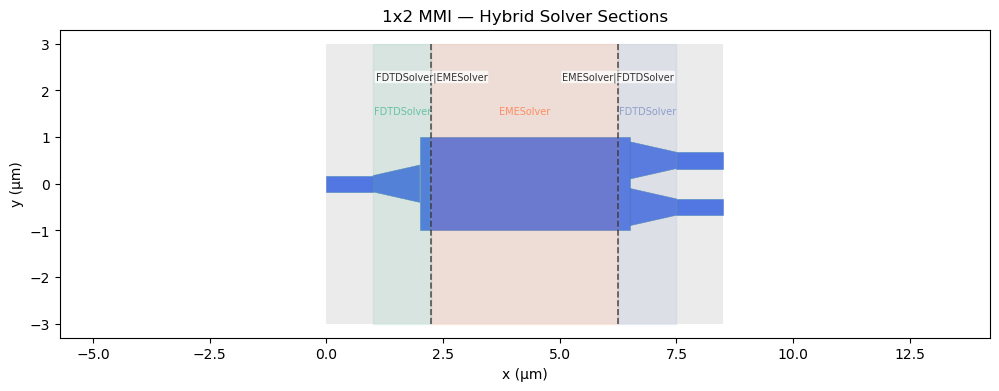

In [6]:
# 4. Geometry plot — shows which solver covers which section
plot_hybrid_geometry(
    mmi, solver=hybrid,
    in_modes=1, out_modes=1,
    title="1x2 MMI — Hybrid Solver Sections",
)
plt.show()

In [ ]:
# 5. Run hybrid simulation — once per output port (output_idx selects the
#    output branch of the MMI geometry: output_ys = [-wo, +wo], so index 0
#    is the bottom port and index 1 is the top port). output_idx is passed
#    ONLY to the output section's kwargs (the input/body sections don't
#    branch, so their kwargs are identical across both calls) and a shared
#    cache is passed to both solve() calls, so the input/body sections are
#    only ever simulated once — not once per output port.
wavelengths = np.linspace(WL_MIN, WL_MAX, N_WL)
print(f"\nHybrid sweep: {wavelengths[0]:.3f} - {wavelengths[-1]:.3f} um "
      f"({len(wavelengths)} pts, {N_MODES} interface modes)\n")

section_cache = {}
smat_top = hybrid.solve(mmi, wavelengths, port="out_top", cache=section_cache,
                         geometry_kwargs=[{}, {}, {"output_idx": 1}])
smat_bot = hybrid.solve(mmi, wavelengths, port="out_bot", cache=section_cache,
                         geometry_kwargs=[{}, {}, {"output_idx": 0}])
smat_top.check_passive()  # sanity: total output power must not exceed 1 at any wavelength
smat_bot.check_passive()

T_top   = smat_top.transmission(port="out_top")
T_bot   = smat_bot.transmission(port="out_bot")
T_total = T_top + T_bot


Hybrid sweep: 1.260 - 1.360 um (11 pts, 12 interface modes)

[Hybrid] Section 1/3: FDTDSolver x=[-3.250, -2.000]  modes 1->12
Using MPI version 4.1, 1 processes


[Hybrid] Section 2/3: EMESolver x=[-2.000, 2.000]  modes 12->12


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)


[Hybrid] Section 3/3: FDTDSolver x=[2.000, 3.250]  modes 12->1
[Hybrid] Section 1/3: FDTDSolver (cached)
[Hybrid] Section 2/3: EMESolver (cached)
[Hybrid] Section 3/3: FDTDSolver x=[2.000, 3.250]  modes 12->1


In [ ]:
# 6. Print summary
wl_c = wavelengths[len(wavelengths) // 2]
idx  = np.argmin(np.abs(wavelengths - wl_c))

print(f"\nResults at wavelength = {wl_c:.3f} um:")
print(f"  Top output    T = {T_top[idx]:.4f}  IL = {10*np.log10(max(T_top[idx],1e-20)):.2f} dB")
print(f"  Bottom output T = {T_bot[idx]:.4f}  IL = {10*np.log10(max(T_bot[idx],1e-20)):.2f} dB")
print(f"  Total         T = {T_total[idx]:.4f}  IL = {10*np.log10(max(T_total[idx],1e-20)):.2f} dB")
print(f"  (ideal 50/50 split: T_each=0.5, IL_total=0.0 dB)")

In [ ]:
# 7. Results plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(wavelengths, T_top,   label="Top output",  color="steelblue")
ax.plot(wavelengths, T_bot,   label="Bot output",  color="darkorange", linestyle="--")
ax.plot(wavelengths, T_total, label="Total",        color="k", lw=1.5)
ax.axhline(0.5, color="gray", linestyle=":", lw=0.8, label="Ideal per-port")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title("Hybrid — Transmission vs Wavelength")
ax.legend(fontsize=8)
ax.grid(True)
ax.set_ylim(0, 1.05)

ax = axes[1]
IL_top = 10 * np.log10(np.clip(T_top,   1e-20, None))
IL_bot = 10 * np.log10(np.clip(T_bot,   1e-20, None))
IL_tot = 10 * np.log10(np.clip(T_total, 1e-20, None))
ax.plot(wavelengths, IL_top, label="Top output",  color="steelblue")
ax.plot(wavelengths, IL_bot, label="Bot output",  color="darkorange", linestyle="--")
ax.plot(wavelengths, IL_tot, label="Total",        color="k", lw=1.5)
ax.axhline(0.0, color="gray", linestyle=":", lw=0.8, label="Lossless")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Insertion Loss (dB)")
ax.set_title("Hybrid — Insertion Loss vs Wavelength")
ax.legend(fontsize=8)
ax.grid(True)

plt.suptitle("1x2 MMI — FDTD/EME Hybrid Simulation", fontsize=11)
plt.tight_layout()
plt.show()